# Johns — ARIMAX & SARIMAX with Open-Meteo Rainfall

This notebook handles **both daily and weekly sales**.

It compares:
- AutoRegressive Integrated Moving Average (ARIMA)
- AutoRegressive Integrated Moving Average with eXogenous variables (ARIMAX)
- Seasonal AutoRegressive Integrated Moving Average (SARIMA)
- Seasonal AutoRegressive Integrated Moving Average with eXogenous variables (SARIMAX)
- walk-forward naive/median baselines

Evaluation:
- rolling time-series cross-validation for model selection
- untouched final test set
- walk-forward final evaluation
- Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), Weighted Absolute Percentage Error (WAPE)

Rainfall:
1. Open-Meteo Geocoding API resolves a place name to latitude/longitude.
2. Open-Meteo Historical Weather API returns daily rainfall.
3. Daily rainfall is joined to daily sales and aggregated to weekly rainfall.

> Change `LOCATION_NAME` to the location that best represents Johns sales. `Kozhikode` is only a default example.

## 1. Install packages

In [1]:
!pip install pandas numpy matplotlib scikit-learn statsmodels requests


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports and configuration

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.statespace.sarimax import SARIMAX

DAILY_SALES_CSV = "../input/johns_daily_sales.csv"
WEEKLY_SALES_CSV = "../input/weekly_sales_history.csv"

LOCATION_NAME = "Kochi"
COUNTRY_CODE = "IN"

SALES_SCALE = 1_000_000.0
RAINY_DAY_THRESHOLD_MM = 0.1

DAILY_TEST_DAYS = 60
WEEKLY_TEST_WEEKS = 12

MAX_CV_FOLDS = 6
DAILY_VALIDATION_DAYS = 14
DAILY_STEP_DAYS = 28
WEEKLY_VALIDATION_WEEKS = 4
WEEKLY_STEP_WEEKS = 4

DAILY_SEASONAL_PERIOD = 7
WEEKLY_SEASONAL_PERIOD = 52

FAST_MODE = True


## 3. Flexible CSV loader

In [3]:
def load_sales_csv(path, date_candidates, sales_candidates, out_date):
    df = pd.read_csv(path)

    date_col = next((c for c in date_candidates if c in df.columns), None)
    sales_col = next((c for c in sales_candidates if c in df.columns), None)

    if date_col is None:
        raise KeyError(f"No supported date column in {path}: {list(df.columns)}")
    if sales_col is None:
        raise KeyError(f"No supported sales column in {path}: {list(df.columns)}")

    out = df[[date_col, sales_col]].rename(
        columns={date_col: out_date, sales_col: "sales"}
    )

    out[out_date] = pd.to_datetime(out[out_date])
    out["sales"] = pd.to_numeric(out["sales"], errors="coerce")

    return out.dropna().sort_values(out_date).reset_index(drop=True)

## 4. Load daily and weekly sales

In [4]:
daily_raw = load_sales_csv(
    DAILY_SALES_CSV,
    ["sale_date", "date", "day"],
    ["daily_sales_total", "daily_sales", "sales"],
    "date"
)

weekly_raw = load_sales_csv(
    WEEKLY_SALES_CSV,
    ["week_ending", "date", "week"],
    ["weekly_sales_total", "weekly_sales", "sales"],
    "week_ending"
)

display(daily_raw.head())
display(weekly_raw.head())

,date,sales
0,2025-01-06,5796829.52
1,2025-01-07,903355.24
2,2025-01-08,121297.50
3,2025-01-09,0.00
4,2025-01-10,357332.86


,week_ending,sales
0,2025-01-12,7178815.12
1,2025-01-19,198122.40
2,2025-01-26,27064954.68
3,2025-02-02,63967214.68
4,2025-02-09,15832570.52


## 5. Complete calendars and fill genuine no-sales periods with zero

In [5]:
daily_idx = pd.date_range(daily_raw["date"].min(), daily_raw["date"].max(), freq="D")
daily_sales = (
    daily_raw.groupby("date")["sales"]
    .sum()
    .reindex(daily_idx, fill_value=0.0)
)
daily_sales.index.name = "date"

weekly_idx = pd.date_range(
    weekly_raw["week_ending"].min(),
    weekly_raw["week_ending"].max(),
    freq="W-SUN"
)
weekly_sales = (
    weekly_raw.groupby("week_ending")["sales"]
    .sum()
    .reindex(weekly_idx, fill_value=0.0)
)
weekly_sales.index.name = "week_ending"

print("Daily:", daily_sales.index.min(), "->", daily_sales.index.max(), len(daily_sales))
print("Weekly:", weekly_sales.index.min(), "->", weekly_sales.index.max(), len(weekly_sales))

Daily: 2025-01-06 00:00:00 -> 2026-08-07 00:00:00 579
Weekly: 2025-01-12 00:00:00 -> 2026-08-02 00:00:00 82


## 6. Data consistency check: weekly CSV vs weekly sales derived from daily CSV

In [6]:
weekly_from_daily = daily_sales.resample("W-SUN").sum()
common = weekly_from_daily.index.intersection(weekly_sales.index)

check = pd.DataFrame({
    "weekly_file": weekly_sales.loc[common],
    "from_daily_file": weekly_from_daily.loc[common]
})
check["difference"] = check["weekly_file"] - check["from_daily_file"]

print("Mean absolute difference:", check["difference"].abs().mean())
print("Maximum absolute difference:", check["difference"].abs().max())
display(check.head(10))

Mean absolute difference: 3.0257335932153025e-11
Maximum absolute difference: 1.862645149230957e-09


,weekly_file,from_daily_file,difference
2025-01-12,7178815.12,7178815.12,0.000000e+00
2025-01-19,198122.40,198122.40,0.000000e+00
2025-01-26,27064954.68,27064954.68,0.000000e+00
2025-02-02,63967214.68,63967214.68,0.000000e+00
2025-02-09,15832570.52,15832570.52,-1.862645e-09
2025-02-16,14850112.48,14850112.48,0.000000e+00
2025-02-23,14801949.52,14801949.52,0.000000e+00
2025-03-02,4170065.72,4170065.72,0.000000e+00
2025-03-09,6615171.52,6615171.52,0.000000e+00
2025-03-16,7194944.12,7194944.12,0.000000e+00


## 7. Plot sales

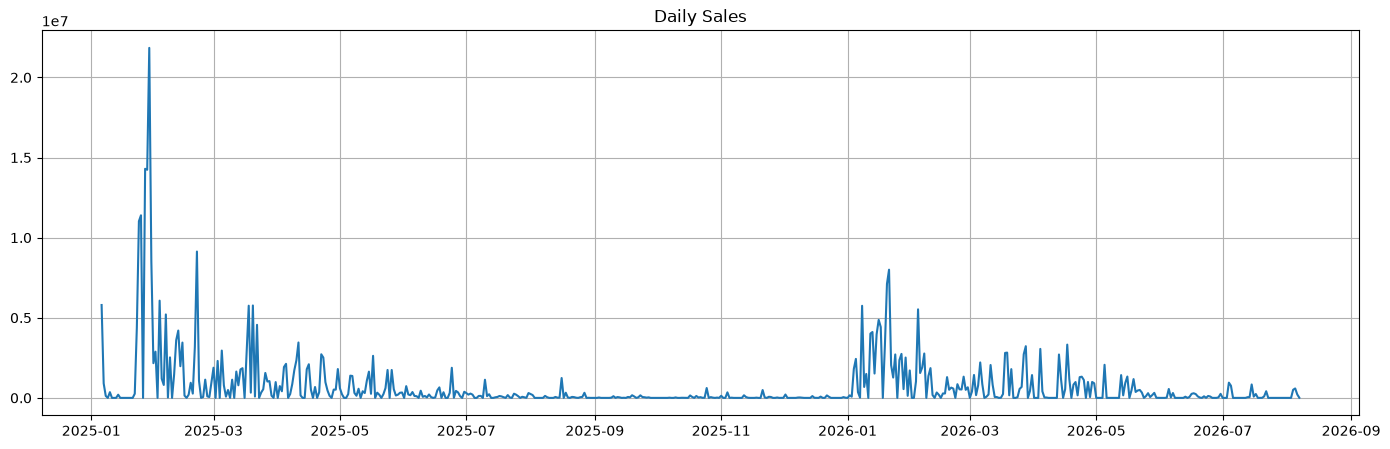

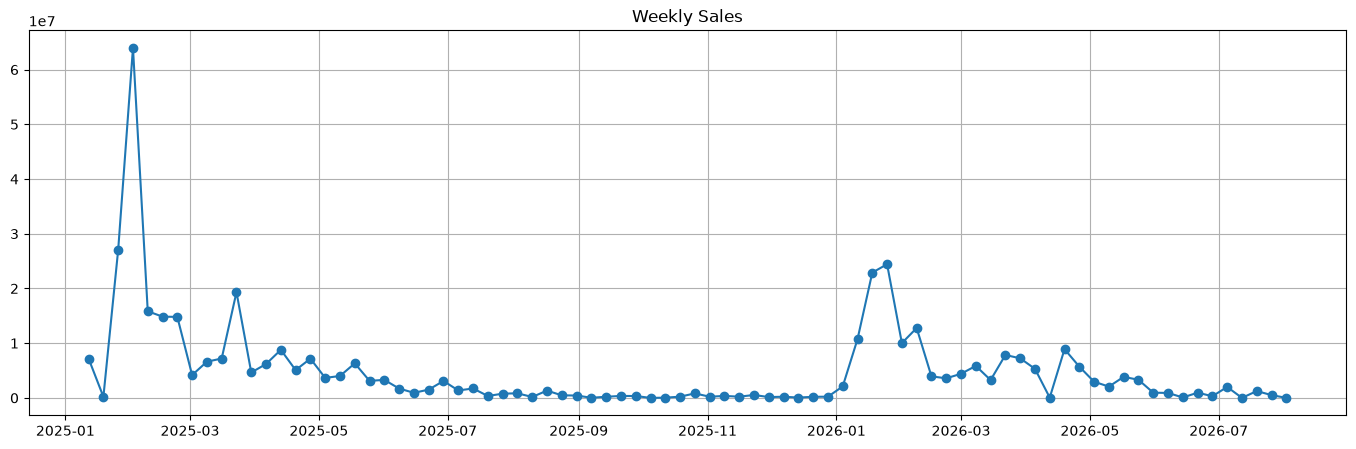

In [7]:
plt.figure(figsize=(17,5))
plt.plot(daily_sales.index, daily_sales.values)
plt.title("Daily Sales")
plt.grid(True)
plt.show()

plt.figure(figsize=(17,5))
plt.plot(weekly_sales.index, weekly_sales.values, marker="o")
plt.title("Weekly Sales")
plt.grid(True)
plt.show()

# Open-Meteo Rainfall

The Geocoding API is used only to resolve the location.  
Historical rainfall is fetched from the Historical Weather API.

## 8. Geocode location

In [ ]:
def geocode_open_meteo(name, country_code=None):
    url = "https://geocoding-api.open-meteo.com/v1/search"
    params = {
        "name": name,
        "count": 10,
        "language": "en",
        "format": "json"
    }
    if country_code:
        params["countryCode"] = country_code

    r = requests.get(url, params=params, timeout=30)
    r.raise_for_status()
    results = r.json().get("results", [])
   
    if not results:
        raise ValueError(f"No geocoding result for {name}")

    x = results[0]
    return {
        "name": x.get("name"),
        "admin1": x.get("admin1"),
        "country": x.get("country"),
        "latitude": x["latitude"],
        "longitude": x["longitude"],
        "timezone": x.get("timezone", "Asia/Kolkata")
    }

location = geocode_open_meteo(LOCATION_NAME, COUNTRY_CODE)
location

{'name': 'Kochi',
 'admin1': 'Kerala',
 'country': 'India',
 'latitude': 9.93988,
 'longitude': 76.26022,
 'timezone': 'Asia/Kolkata'}

## 9. Fetch historical rainfall

In [9]:
def fetch_historical_rain(lat, lon, start_date, end_date, timezone):
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": pd.Timestamp(start_date).strftime("%Y-%m-%d"),
        "end_date": pd.Timestamp(end_date).strftime("%Y-%m-%d"),
        "daily": "rain_sum,precipitation_sum,precipitation_hours",
        "timezone": timezone,
        "precipitation_unit": "mm"
    }

    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    payload = r.json()

    weather = pd.DataFrame(payload["daily"])
    weather["date"] = pd.to_datetime(weather["time"])
    weather = weather.drop(columns=["time"])
    weather["rainy_day"] = (
        weather["rain_sum"] >= RAINY_DAY_THRESHOLD_MM
    ).astype(int)
    return weather

weather_start = min(daily_sales.index.min(), weekly_sales.index.min())
weather_end = max(daily_sales.index.max(), weekly_sales.index.max())

weather_daily = fetch_historical_rain(
    location["latitude"],
    location["longitude"],
    weather_start,
    weather_end,
    location["timezone"]
)

display(weather_daily.tail(10))
display(weather_daily[weather_daily["date"].between("2025-07-01", "2025-07-31")])


,rain_sum,precipitation_sum,precipitation_hours,date,rainy_day
569,12.2,12.2,14.0,2026-07-29,1
570,16.2,16.2,16.0,2026-07-30,1
571,49.7,49.7,22.0,2026-07-31,1
572,92.1,92.1,24.0,2026-08-01,1
573,40.4,40.4,23.0,2026-08-02,1
574,37.3,37.3,20.0,2026-08-03,1
575,16.0,16.0,23.0,2026-08-04,1
576,8.3,8.3,9.0,2026-08-05,1
577,34.5,34.5,24.0,2026-08-06,1
578,24.0,24.0,23.0,2026-08-07,1


,rain_sum,precipitation_sum,precipitation_hours,date,rainy_day
176,6.4,6.4,18.0,2025-07-01,1
177,15.2,15.2,18.0,2025-07-02,1
178,4.4,4.4,10.0,2025-07-03,1
179,2.9,2.9,7.0,2025-07-04,1
180,1.8,1.8,7.0,2025-07-05,1
181,8.3,8.3,21.0,2025-07-06,1
182,2.2,2.2,14.0,2025-07-07,1
183,5.8,5.8,16.0,2025-07-08,1
184,4.4,4.4,12.0,2025-07-09,1
185,5.1,5.1,15.0,2025-07-10,1


## 10. Build daily and weekly modeling tables

In [10]:
daily_df = (
    daily_sales.rename("sales").to_frame().reset_index()
    .merge(
        weather_daily[["date", "rain_sum", "precipitation_hours", "rainy_day"]],
        on="date",
        how="left"
    )
    .set_index("date")
)

daily_exog = ["rain_sum", "precipitation_hours", "rainy_day"]
daily_df[daily_exog] = daily_df[daily_exog].fillna(0.0)

weather_weekly = (
    weather_daily.set_index("date")
    .resample("W-SUN")
    .agg({
        "rain_sum": ["sum", "max"],
        "precipitation_hours": "sum",
        "rainy_day": "sum"
    })
)
weather_weekly.columns = [
    "rain_sum_week",
    "max_daily_rain",
    "precipitation_hours_week",
    "rainy_days"
]

weekly_df = weekly_sales.rename("sales").to_frame().join(weather_weekly, how="left")
weekly_exog = [
    "rain_sum_week",
    "max_daily_rain",
    "precipitation_hours_week",
    "rainy_days"
]
weekly_df[weekly_exog] = weekly_df[weekly_exog].fillna(0.0)

display(daily_df.head())
display(weekly_df.head())

,sales,rain_sum,precipitation_hours,rainy_day
date,,,,
2025-01-06,5796829.52,0.0,0.0,0
2025-01-07,903355.24,0.0,0.0,0
2025-01-08,121297.50,0.4,2.0,1
2025-01-09,0.00,0.0,0.0,0
2025-01-10,357332.86,0.0,0.0,0


,sales,rain_sum_week,max_daily_rain,precipitation_hours_week,rainy_days
week_ending,,,,,
2025-01-12,7178815.12,1.4,0.6,5.0,3
2025-01-19,198122.40,7.3,2.5,30.0,4
2025-01-26,27064954.68,0.8,0.8,4.0,1
2025-02-02,63967214.68,6.7,2.6,16.0,3
2025-02-09,15832570.52,1.1,1.1,4.0,1


## 11. Rainfall/sales correlation diagnostic

In [11]:
print("Daily:")
display(daily_df[["sales"] + daily_exog].corr())

print("Weekly:")
display(weekly_df[["sales"] + weekly_exog].corr())

Daily:


,sales,rain_sum,precipitation_hours,rainy_day
sales,1.000000,-0.143546,-0.253785,-0.261095
rain_sum,-0.143546,1.000000,0.730643,0.270130
precipitation_hours,-0.253785,0.730643,1.000000,0.507597
rainy_day,-0.261095,0.270130,0.507597,1.000000


Weekly:


,sales,rain_sum_week,max_daily_rain,precipitation_hours_week,rainy_days
sales,1.000000,-0.277579,-0.287922,-0.396235,-0.391272
rain_sum_week,-0.277579,1.000000,0.970287,0.854727,0.450893
max_daily_rain,-0.287922,0.970287,1.000000,0.821796,0.453695
precipitation_hours_week,-0.396235,0.854727,0.821796,1.000000,0.647849
rainy_days,-0.391272,0.450893,0.453695,0.647849,1.000000


# Modeling utilities

## 12. Metrics

In [12]:
def wape(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    denom = np.sum(np.abs(actual))
    if denom == 0:
        return np.nan
    return np.sum(np.abs(actual - predicted)) / denom * 100

def get_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "WAPE": wape(actual, predicted)
    }

## 13. Split, exogenous scaling, fit/forecast

In [13]:
def split_time(df, test_size):
    return df.iloc[:-test_size].copy(), df.iloc[-test_size:].copy()

def scale_exog(train_x, future_x):
    mu = train_x.mean()
    sigma = train_x.std(ddof=0).replace(0, 1.0)
    return (train_x - mu) / sigma, (future_x - mu) / sigma

def fit_forecast_once(
    train_y,
    steps,
    order,
    seasonal_order=(0,0,0,0),
    train_exog=None,
    future_exog=None
):
    model = SARIMAX(
        train_y.astype(float) / SALES_SCALE,
        exog=train_exog,
        order=order,
        seasonal_order=seasonal_order,
        trend="n",
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    result = model.fit(disp=False, maxiter=150)
    pred = result.get_forecast(steps=steps, exog=future_exog).predicted_mean
    pred = np.asarray(pred, dtype=float) * SALES_SCALE
    return np.clip(pred, 0, None)

## 14. Rolling cross-validation

In [14]:
def make_folds(n, val_size, step, max_folds):
    initial = max(n // 2, val_size * 3)
    origins = list(range(initial, n - val_size + 1, step))
    origins = origins[-max_folds:]
    return [(o, o + val_size) for o in origins if o + val_size <= n]

def rolling_cv(
    train_df,
    target,
    exog_cols,
    configs,
    val_size,
    step,
    max_folds
):
    folds = make_folds(len(train_df), val_size, step, max_folds)
    rows = []

    for cfg in configs:
        metrics = []

        for train_end, val_end in folds:
            tr = train_df.iloc[:train_end]
            va = train_df.iloc[train_end:val_end]

            try:
                if exog_cols:
                    tr_x, va_x = scale_exog(tr[exog_cols], va[exog_cols])
                else:
                    tr_x = va_x = None

                pred = fit_forecast_once(
                    tr[target],
                    len(va),
                    cfg["order"],
                    cfg["seasonal_order"],
                    tr_x,
                    va_x
                )
                metrics.append(get_metrics(va[target], pred))
            except Exception as e:
                print("Skipped:", cfg["label"], type(e).__name__, str(e)[:80])

        if metrics:
            m = pd.DataFrame(metrics)
            rows.append({
                "label": cfg["label"],
                "order": cfg["order"],
                "seasonal_order": cfg["seasonal_order"],
                "folds": len(m),
                "mean_MAE": m["MAE"].mean(),
                "mean_RMSE": m["RMSE"].mean(),
                "mean_WAPE": m["WAPE"].mean(),
                "median_WAPE": m["WAPE"].median()
            })

    return pd.DataFrame(rows).sort_values("mean_WAPE").reset_index(drop=True)

## 15. Walk-forward final test

In [15]:
def walk_forward_model(train_df, test_df, target, exog_cols, order, seasonal_order):
    history = train_df.copy()
    preds = []

    for i in range(len(test_df)):
        current = test_df.iloc[[i]]

        if exog_cols:
            tr_x, future_x = scale_exog(history[exog_cols], current[exog_cols])
        else:
            tr_x = future_x = None

        pred = fit_forecast_once(
            history[target],
            1,
            order,
            seasonal_order,
            tr_x,
            future_x
        )[0]

        preds.append(pred)
        history = pd.concat([history, current])

    return np.asarray(preds)

def walk_forward_naive(train_y, test_y):
    h = list(train_y.values)
    p = []
    for actual in test_y.values:
        p.append(h[-1])
        h.append(float(actual))
    return np.asarray(p)

def walk_forward_median(train_y, test_y, window):
    h = list(train_y.values)
    p = []
    for actual in test_y.values:
        p.append(np.median(h[-window:]))
        h.append(float(actual))
    return np.asarray(p)

## 16. Candidate orders

In [16]:
if FAST_MODE:
    ORDERS = [
        (1,0,0),
        (1,1,0),
        (0,1,1),
        (1,1,1),
        (2,1,1)
    ]
else:
    ORDERS = [
        (p,d,q)
        for p in range(4)
        for d in [0,1]
        for q in range(4)
        if (p,d,q) != (0,0,0)
    ]

def configs_nonseasonal(prefix):
    return [
        {
            "label": f"{prefix}{o}",
            "order": o,
            "seasonal_order": (0,0,0,0)
        }
        for o in ORDERS
    ]

def configs_daily_seasonal(prefix):
    base = [(1,0,0), (1,1,1), (0,1,1)]
    seas = [
        (1,0,0,7),
        (0,1,1,7),
        (1,0,1,7)
    ]
    return [
        {
            "label": f"{prefix}{o}x{s}",
            "order": o,
            "seasonal_order": s
        }
        for o in base for s in seas
    ]

def configs_weekly_seasonal(prefix):
    base = [(1,0,0), (1,1,1), (0,1,1)]
    seas = [
        (1,0,0,52),
        (0,0,1,52)
    ]
    return [
        {
            "label": f"{prefix}{o}x{s}",
            "order": o,
            "seasonal_order": s
        }
        for o in base for s in seas
    ]

def best_cfg(cv):
    r = cv.iloc[0]
    return {
        "label": r["label"],
        "order": tuple(r["order"]),
        "seasonal_order": tuple(r["seasonal_order"])
    }

# DAILY SALES — ARIMA, ARIMAX, SARIMA, SARIMAX

## 17. Daily split

In [17]:
daily_train, daily_test = split_time(daily_df, DAILY_TEST_DAYS)

print("Train:", daily_train.index.min(), "->", daily_train.index.max(), len(daily_train))
print("Test :", daily_test.index.min(), "->", daily_test.index.max(), len(daily_test))

Train: 2025-01-06 00:00:00 -> 2026-06-08 00:00:00 519
Test : 2026-06-09 00:00:00 -> 2026-08-07 00:00:00 60


## 18. Daily rolling cross-validation

In [18]:
daily_arima_cv = rolling_cv(
    daily_train, "sales", [], configs_nonseasonal("ARIMA"),
    DAILY_VALIDATION_DAYS, DAILY_STEP_DAYS, MAX_CV_FOLDS
)

daily_arimax_cv = rolling_cv(
    daily_train, "sales", daily_exog, configs_nonseasonal("ARIMAX"),
    DAILY_VALIDATION_DAYS, DAILY_STEP_DAYS, MAX_CV_FOLDS
)

daily_sarima_cv = rolling_cv(
    daily_train, "sales", [], configs_daily_seasonal("SARIMA"),
    DAILY_VALIDATION_DAYS, DAILY_STEP_DAYS, MAX_CV_FOLDS
)

daily_sarimax_cv = rolling_cv(
    daily_train, "sales", daily_exog, configs_daily_seasonal("SARIMAX"),
    DAILY_VALIDATION_DAYS, DAILY_STEP_DAYS, MAX_CV_FOLDS
)

print("ARIMA"); display(daily_arima_cv)
print("ARIMAX"); display(daily_arimax_cv)
print("SARIMA"); display(daily_sarima_cv)
print("SARIMAX"); display(daily_sarimax_cv)

c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\adithyankg\OneDrive

ARIMA


,label,order,seasonal_order,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE
0,"ARIMA(1, 0, 0)","(1, 0, 0)","(0, 0, 0, 0)",6,9.733201e+05,1.376195e+06,100.992417,100.000000
1,"ARIMA(1, 1, 0)","(1, 1, 0)","(0, 0, 0, 0)",6,9.749266e+05,1.258188e+06,107.743129,98.641608
2,"ARIMA(0, 1, 1)","(0, 1, 1)","(0, 0, 0, 0)",6,9.932882e+05,1.215870e+06,121.030468,110.424321
3,"ARIMA(1, 1, 1)","(1, 1, 1)","(0, 0, 0, 0)",6,1.100327e+06,1.301059e+06,138.357995,139.956346
4,"ARIMA(2, 1, 1)","(2, 1, 1)","(0, 0, 0, 0)",6,1.116197e+06,1.294250e+06,142.624995,153.987974


ARIMAX


,label,order,seasonal_order,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE
0,"ARIMAX(1, 1, 0)","(1, 1, 0)","(0, 0, 0, 0)",6,9.616919e+05,1.269494e+06,105.672469,97.361379
1,"ARIMAX(0, 1, 1)","(0, 1, 1)","(0, 0, 0, 0)",6,9.856777e+05,1.219174e+06,118.616819,111.419944
2,"ARIMAX(1, 1, 1)","(1, 1, 1)","(0, 0, 0, 0)",6,1.082990e+06,1.301971e+06,352.569708,140.410178
3,"ARIMAX(1, 0, 0)","(1, 0, 0)","(0, 0, 0, 0)",6,1.025146e+06,1.414593e+06,377.743312,97.809067
4,"ARIMAX(2, 1, 1)","(2, 1, 1)","(0, 0, 0, 0)",6,1.159817e+06,1.369331e+06,384.392761,148.525698


SARIMA


,label,order,seasonal_order,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE
0,"SARIMA(1, 0, 0)x(1, 0, 1, 7)","(1, 0, 0)","(1, 0, 1, 7)",6,9.593136e+05,1.366179e+06,99.881710,100.000000
1,"SARIMA(1, 0, 0)x(1, 0, 0, 7)","(1, 0, 0)","(1, 0, 0, 7)",6,9.679620e+05,1.361373e+06,101.419813,98.863937
2,"SARIMA(0, 1, 1)x(1, 0, 0, 7)","(0, 1, 1)","(1, 0, 0, 7)",6,9.933390e+05,1.212881e+06,120.748411,110.504596
3,"SARIMA(1, 1, 1)x(1, 0, 0, 7)","(1, 1, 1)","(1, 0, 0, 7)",6,1.134279e+06,1.314650e+06,145.208095,142.425501
4,"SARIMA(0, 1, 1)x(1, 0, 1, 7)","(0, 1, 1)","(1, 0, 1, 7)",6,1.050966e+06,1.281295e+06,151.685875,148.659501
5,"SARIMA(1, 0, 0)x(0, 1, 1, 7)","(1, 0, 0)","(0, 1, 1, 7)",6,1.029236e+06,1.250736e+06,160.450730,121.260006
6,"SARIMA(1, 1, 1)x(0, 1, 1, 7)","(1, 1, 1)","(0, 1, 1, 7)",6,1.026120e+06,1.224570e+06,166.312562,146.265093
7,"SARIMA(1, 1, 1)x(1, 0, 1, 7)","(1, 1, 1)","(1, 0, 1, 7)",6,1.026785e+06,1.267251e+06,166.317398,135.571135
8,"SARIMA(0, 1, 1)x(0, 1, 1, 7)","(0, 1, 1)","(0, 1, 1, 7)",6,1.053173e+06,1.240839e+06,179.139187,152.270341


SARIMAX


,label,order,seasonal_order,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE
0,"SARIMAX(0, 1, 1)x(1, 0, 0, 7)","(0, 1, 1)","(1, 0, 0, 7)",6,9.848295e+05,1.224751e+06,127.715207,120.495053
1,"SARIMAX(0, 1, 1)x(1, 0, 1, 7)","(0, 1, 1)","(1, 0, 1, 7)",6,1.033484e+06,1.277630e+06,137.116354,146.834134
2,"SARIMAX(1, 1, 1)x(1, 0, 1, 7)","(1, 1, 1)","(1, 0, 1, 7)",6,1.030038e+06,1.280880e+06,171.776150,136.969639
3,"SARIMAX(0, 1, 1)x(0, 1, 1, 7)","(0, 1, 1)","(0, 1, 1, 7)",6,1.034460e+06,1.240934e+06,172.749061,151.682665
4,"SARIMAX(1, 1, 1)x(0, 1, 1, 7)","(1, 1, 1)","(0, 1, 1, 7)",6,1.141903e+06,1.354158e+06,188.077609,147.357821
5,"SARIMAX(1, 1, 1)x(1, 0, 0, 7)","(1, 1, 1)","(1, 0, 0, 7)",6,1.128805e+06,1.334948e+06,352.400916,146.566882
6,"SARIMAX(1, 0, 0)x(1, 0, 1, 7)","(1, 0, 0)","(1, 0, 1, 7)",6,1.027128e+06,1.435264e+06,368.632567,101.307963
7,"SARIMAX(1, 0, 0)x(1, 0, 0, 7)","(1, 0, 0)","(1, 0, 0, 7)",6,1.023409e+06,1.409880e+06,368.996944,98.452325
8,"SARIMAX(1, 0, 0)x(0, 1, 1, 7)","(1, 0, 0)","(0, 1, 1, 7)",6,1.088173e+06,1.325702e+06,436.057375,121.517002


## 19. Daily walk-forward test

In [30]:
bd_arima = best_cfg(daily_arima_cv)
bd_arimax = best_cfg(daily_arimax_cv)
bd_sarima = best_cfg(daily_sarima_cv)
bd_sarimax = best_cfg(daily_sarimax_cv)

d_naive = walk_forward_naive(daily_train["sales"], daily_test["sales"])
d_med7 = walk_forward_median(daily_train["sales"], daily_test["sales"], 7)

d_arima = walk_forward_model(
    daily_train, daily_test, "sales", [],
    bd_arima["order"], bd_arima["seasonal_order"]
)

d_arimax = walk_forward_model(
    daily_train, daily_test, "sales", daily_exog,
    bd_arimax["order"], bd_arimax["seasonal_order"]
)

d_sarima = walk_forward_model(
    daily_train, daily_test, "sales", [],
    bd_sarima["order"], bd_sarima["seasonal_order"]
)

d_sarimax = walk_forward_model(
    daily_train, daily_test, "sales", daily_exog,
    bd_sarimax["order"], bd_sarimax["seasonal_order"]
)

c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\adithyankg\OneDrive

## 20. Daily final comparison

In [20]:
daily_comparison = pd.DataFrame([
    {"Model":"Naive", **get_metrics(daily_test["sales"], d_naive)},
    {"Model":"7-Day Median", **get_metrics(daily_test["sales"], d_med7)},
    {"Model":"ARIMA", **get_metrics(daily_test["sales"], d_arima)},
    {"Model":"ARIMAX + Rainfall", **get_metrics(daily_test["sales"], d_arimax)},
    {"Model":"SARIMA", **get_metrics(daily_test["sales"], d_sarima)},
    {"Model":"SARIMAX + Rainfall", **get_metrics(daily_test["sales"], d_sarimax)}
]).sort_values("WAPE").reset_index(drop=True)

daily_comparison

,Model,MAE,RMSE,WAPE
0,ARIMA,107567.458334,216852.730405,100.768360
1,SARIMA,107806.244537,212488.106469,100.992053
2,7-Day Median,108590.932667,234251.608252,101.727143
3,Naive,126042.248000,250438.331705,118.075399
4,ARIMAX + Rainfall,136127.160417,245444.786788,127.522867
5,SARIMAX + Rainfall,141287.310565,231388.240567,132.356856


## 21. Daily forecast plot

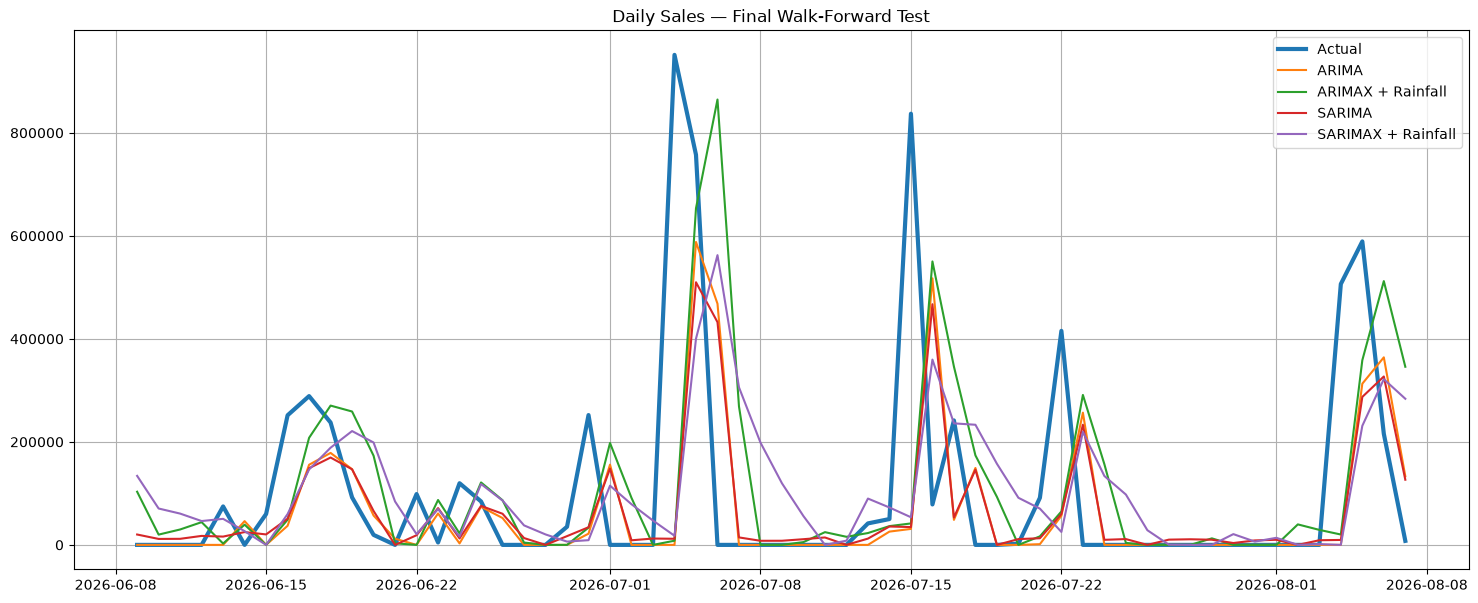

In [21]:
plt.figure(figsize=(18,7))
plt.plot(daily_test.index, daily_test["sales"], label="Actual", linewidth=3)
plt.plot(daily_test.index, d_arima, label="ARIMA")
plt.plot(daily_test.index, d_arimax, label="ARIMAX + Rainfall")
plt.plot(daily_test.index, d_sarima, label="SARIMA")
plt.plot(daily_test.index, d_sarimax, label="SARIMAX + Rainfall")
plt.title("Daily Sales — Final Walk-Forward Test")
plt.legend()
plt.grid(True)
plt.show()

# WEEKLY SALES — ARIMA, ARIMAX, SARIMA, SARIMAX

## 22. Weekly split and seasonality warning

In [22]:
weekly_train, weekly_test = split_time(weekly_df, WEEKLY_TEST_WEEKS)

print("Train:", weekly_train.index.min(), "->", weekly_train.index.max(), len(weekly_train))
print("Test :", weekly_test.index.min(), "->", weekly_test.index.max(), len(weekly_test))

if len(weekly_train) < 104:
    print(
        "WARNING: less than two complete 52-week cycles are available. "
        "Weekly 52-period SARIMA/SARIMAX is exploratory."
    )

Train: 2025-01-12 00:00:00 -> 2026-05-10 00:00:00 70
Test : 2026-05-17 00:00:00 -> 2026-08-02 00:00:00 12


## 23. Weekly rolling cross-validation

In [23]:
weekly_arima_cv = rolling_cv(
    weekly_train, "sales", [], configs_nonseasonal("ARIMA"),
    WEEKLY_VALIDATION_WEEKS, WEEKLY_STEP_WEEKS, MAX_CV_FOLDS
)

weekly_arimax_cv = rolling_cv(
    weekly_train, "sales", weekly_exog, configs_nonseasonal("ARIMAX"),
    WEEKLY_VALIDATION_WEEKS, WEEKLY_STEP_WEEKS, MAX_CV_FOLDS
)

weekly_sarima_cv = rolling_cv(
    weekly_train, "sales", [], configs_weekly_seasonal("SARIMA"),
    WEEKLY_VALIDATION_WEEKS, WEEKLY_STEP_WEEKS, MAX_CV_FOLDS
)

weekly_sarimax_cv = rolling_cv(
    weekly_train, "sales", weekly_exog, configs_weekly_seasonal("SARIMAX"),
    WEEKLY_VALIDATION_WEEKS, WEEKLY_STEP_WEEKS, MAX_CV_FOLDS
)

print("ARIMA"); display(weekly_arima_cv)
print("ARIMAX"); display(weekly_arimax_cv)
print("SARIMA"); display(weekly_sarima_cv)
print("SARIMAX"); display(weekly_sarimax_cv)

c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\adithyankg\OneDrive\Pictures\statistical_models\.venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warning

ARIMA


,label,order,seasonal_order,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE
0,"ARIMA(1, 1, 1)","(1, 1, 1)","(0, 0, 0, 0)",6,4.416832e+06,5.228065e+06,66.658597,65.711990
1,"ARIMA(1, 0, 0)","(1, 0, 0)","(0, 0, 0, 0)",6,4.321213e+06,5.059513e+06,71.489354,73.039102
2,"ARIMA(2, 1, 1)","(2, 1, 1)","(0, 0, 0, 0)",6,4.860718e+06,5.759061e+06,71.525556,60.940179
3,"ARIMA(0, 1, 1)","(0, 1, 1)","(0, 0, 0, 0)",6,4.977675e+06,5.755704e+06,74.008965,65.348512
4,"ARIMA(1, 1, 0)","(1, 1, 0)","(0, 0, 0, 0)",6,6.035411e+06,6.808075e+06,78.732885,44.617448


ARIMAX


,label,order,seasonal_order,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE
0,"ARIMAX(2, 1, 1)","(2, 1, 1)","(0, 0, 0, 0)",6,5.219544e+06,6.094981e+06,85.243893,84.373169
1,"ARIMAX(1, 1, 1)","(1, 1, 1)","(0, 0, 0, 0)",6,4.958842e+06,5.855516e+06,140.309565,101.599545
2,"ARIMAX(1, 0, 0)","(1, 0, 0)","(0, 0, 0, 0)",6,4.518407e+06,5.301457e+06,188.130867,75.825563
3,"ARIMAX(1, 1, 0)","(1, 1, 0)","(0, 0, 0, 0)",6,6.108492e+06,6.920805e+06,239.023103,149.938664
4,"ARIMAX(0, 1, 1)","(0, 1, 1)","(0, 0, 0, 0)",6,7.533866e+06,8.588962e+06,1055.870561,128.264959


SARIMA


,label,order,seasonal_order,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE
0,"SARIMA(0, 1, 1)x(0, 0, 1, 52)","(0, 1, 1)","(0, 0, 1, 52)",6,5.955829e+06,6.731707e+06,79.706680,46.260655
1,"SARIMA(1, 1, 1)x(0, 0, 1, 52)","(1, 1, 1)","(0, 0, 1, 52)",6,6.076139e+06,6.812551e+06,85.527533,53.658038
2,"SARIMA(0, 1, 1)x(1, 0, 0, 52)","(0, 1, 1)","(1, 0, 0, 52)",6,6.911791e+06,7.591012e+06,98.682435,86.098165
3,"SARIMA(1, 0, 0)x(0, 0, 1, 52)","(1, 0, 0)","(0, 0, 1, 52)",6,9.725871e+06,1.087430e+07,141.299786,74.522012
4,"SARIMA(1, 0, 0)x(1, 0, 0, 52)","(1, 0, 0)","(1, 0, 0, 52)",6,2.416530e+07,2.933247e+07,331.814922,74.522012
5,"SARIMA(1, 1, 1)x(1, 0, 0, 52)","(1, 1, 1)","(1, 0, 0, 52)",6,3.984360e+07,5.042447e+07,535.271540,76.759936


SARIMAX


,label,order,seasonal_order,folds,mean_MAE,mean_RMSE,mean_WAPE,median_WAPE
0,"SARIMAX(1, 1, 1)x(0, 0, 1, 52)","(1, 1, 1)","(0, 0, 1, 52)",6,7.505647e+06,8.476193e+06,365.110757,170.827729
1,"SARIMAX(0, 1, 1)x(1, 0, 0, 52)","(0, 1, 1)","(1, 0, 0, 52)",6,1.830608e+07,2.130152e+07,558.017127,379.786093
2,"SARIMAX(1, 1, 1)x(1, 0, 0, 52)","(1, 1, 1)","(1, 0, 0, 52)",6,1.808376e+07,2.085583e+07,562.883933,384.813965
3,"SARIMAX(0, 1, 1)x(0, 0, 1, 52)","(0, 1, 1)","(0, 0, 1, 52)",6,1.953826e+07,2.287189e+07,583.630441,361.323128
4,"SARIMAX(1, 0, 0)x(0, 0, 1, 52)","(1, 0, 0)","(0, 0, 1, 52)",6,2.744864e+07,3.456245e+07,1569.752072,813.162593
5,"SARIMAX(1, 0, 0)x(1, 0, 0, 52)","(1, 0, 0)","(1, 0, 0, 52)",6,4.193900e+07,5.119873e+07,1791.274042,1124.520114


## 24. Weekly walk-forward test

In [24]:
bw_arima = best_cfg(weekly_arima_cv)
bw_arimax = best_cfg(weekly_arimax_cv)
bw_sarima = best_cfg(weekly_sarima_cv)
bw_sarimax = best_cfg(weekly_sarimax_cv)

w_naive = walk_forward_naive(weekly_train["sales"], weekly_test["sales"])
w_med4 = walk_forward_median(weekly_train["sales"], weekly_test["sales"], 4)

w_arima = walk_forward_model(
    weekly_train, weekly_test, "sales", [],
    bw_arima["order"], bw_arima["seasonal_order"]
)

w_arimax = walk_forward_model(
    weekly_train, weekly_test, "sales", weekly_exog,
    bw_arimax["order"], bw_arimax["seasonal_order"]
)

w_sarima = walk_forward_model(
    weekly_train, weekly_test, "sales", [],
    bw_sarima["order"], bw_sarima["seasonal_order"]
)

w_sarimax = walk_forward_model(
    weekly_train, weekly_test, "sales", weekly_exog,
    bw_sarimax["order"], bw_sarimax["seasonal_order"]
)

## 25. Weekly final comparison

In [25]:
weekly_comparison = pd.DataFrame([
    {"Model":"Naive", **get_metrics(weekly_test["sales"], w_naive)},
    {"Model":"4-Week Median", **get_metrics(weekly_test["sales"], w_med4)},
    {"Model":"ARIMA", **get_metrics(weekly_test["sales"], w_arima)},
    {"Model":"ARIMAX + Rainfall", **get_metrics(weekly_test["sales"], w_arimax)},
    {"Model":"SARIMA", **get_metrics(weekly_test["sales"], w_sarima)},
    {"Model":"SARIMAX + Rainfall", **get_metrics(weekly_test["sales"], w_sarimax)}
]).sort_values("WAPE").reset_index(drop=True)

weekly_comparison

,Model,MAE,RMSE,WAPE
0,4-Week Median,9.178909e+05,1.166149e+06,78.142952
1,SARIMA,9.898856e+05,1.157858e+06,84.272092
2,ARIMAX + Rainfall,1.086959e+06,1.396324e+06,92.536251
3,Naive,1.104140e+06,1.293714e+06,93.998918
4,ARIMA,1.248455e+06,1.479223e+06,106.284959
5,SARIMAX + Rainfall,1.989598e+06,3.355287e+06,169.380750


## 26. Weekly forecast plot

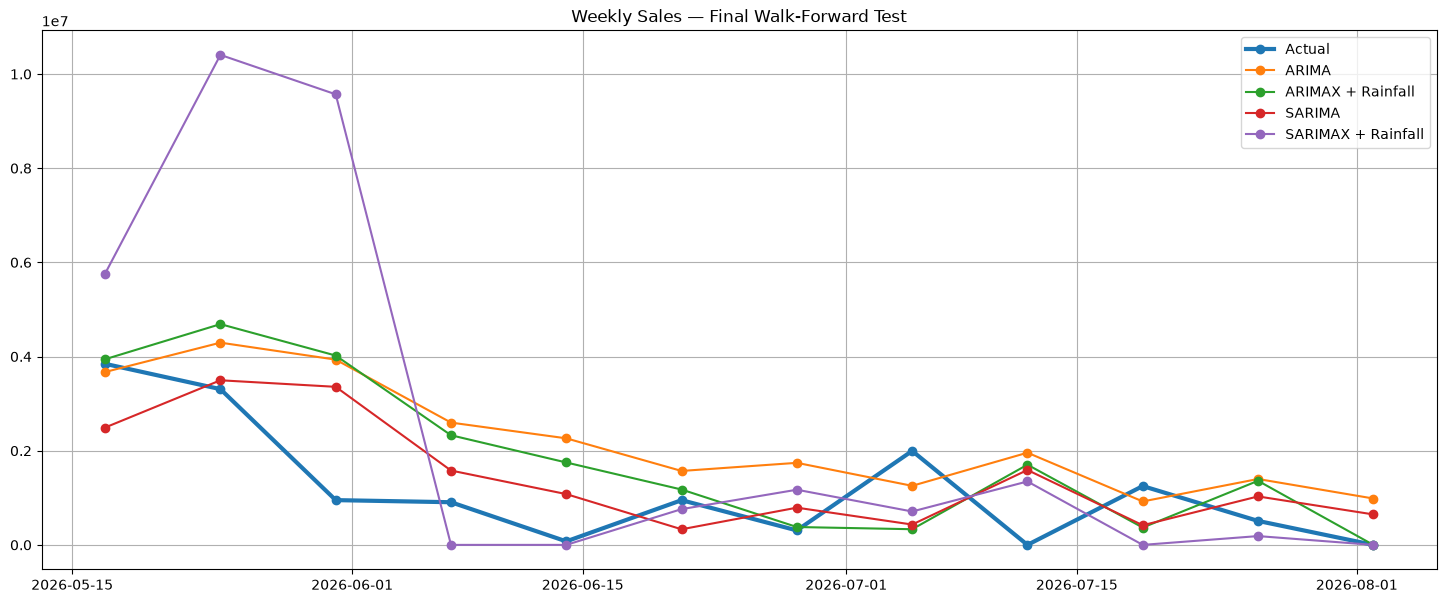

In [26]:
plt.figure(figsize=(18,7))
plt.plot(weekly_test.index, weekly_test["sales"], marker="o", label="Actual", linewidth=3)
plt.plot(weekly_test.index, w_arima, marker="o", label="ARIMA")
plt.plot(weekly_test.index, w_arimax, marker="o", label="ARIMAX + Rainfall")
plt.plot(weekly_test.index, w_sarima, marker="o", label="SARIMA")
plt.plot(weekly_test.index, w_sarimax, marker="o", label="SARIMAX + Rainfall")
plt.title("Weekly Sales — Final Walk-Forward Test")
plt.legend()
plt.grid(True)
plt.show()

# Short-Horizon Future Rainfall

ARIMAX and SARIMAX require future explanatory-variable values.

For rainfall, actual future rainfall is not available. The Open-Meteo Forecast API can supply forecast rainfall for up to 16 days, so this is useful mainly for **short-horizon daily forecasting**.

For multi-month forecasting, rainfall must come from scenarios/seasonal information, not historical actual rainfall.

## 27. Fetch forecast rainfall

In [27]:
def fetch_forecast_rain(lat, lon, timezone, forecast_days=16):
    url = "https://api.open-meteo.com/v1/forecast"
    params = {
        "latitude": lat,
        "longitude": lon,
        "daily": "rain_sum,precipitation_sum,precipitation_hours",
        "timezone": timezone,
        "forecast_days": min(forecast_days, 16),
        "precipitation_unit": "mm"
    }

    r = requests.get(url, params=params, timeout=30)
    r.raise_for_status()

    x = pd.DataFrame(r.json()["daily"])
    x["date"] = pd.to_datetime(x["time"])
    x = x.drop(columns=["time"])
    x["rainy_day"] = (x["rain_sum"] >= RAINY_DAY_THRESHOLD_MM).astype(int)
    return x

future_weather = fetch_forecast_rain(
    location["latitude"],
    location["longitude"],
    location["timezone"],
    16
)

future_weather

,rain_sum,precipitation_sum,precipitation_hours,date,rainy_day
0,1.5,2.70,9.0,2026-08-12,1
1,2.3,4.30,15.0,2026-08-13,1
2,4.2,12.20,20.0,2026-08-14,1
3,3.2,5.70,12.0,2026-08-15,1
4,0.9,2.10,12.0,2026-08-16,1
5,2.4,3.60,9.0,2026-08-17,1
6,0.6,1.20,12.0,2026-08-18,1
7,1.8,3.00,18.0,2026-08-19,1
8,2.4,6.00,12.0,2026-08-20,1
9,3.0,7.20,24.0,2026-08-21,1


## 28. Optional future DAILY SARIMAX forecast

In [28]:
first_weather_date = future_weather["date"].min()
gap_days = (first_weather_date - daily_df.index.max()).days

print("Last sales date:", daily_df.index.max())
print("First weather forecast date:", first_weather_date)
print("Gap:", gap_days, "days")

if gap_days <= 1:
    future_x = (
        future_weather.set_index("date")[daily_exog]
        .loc[lambda x: x.index > daily_df.index.max()]
    )

    if len(future_x):
        train_x_scaled, future_x_scaled = scale_exog(
            daily_df[daily_exog],
            future_x
        )

        model = SARIMAX(
            daily_df["sales"] / SALES_SCALE,
            exog=train_x_scaled,
            order=bd_sarimax["order"],
            seasonal_order=bd_sarimax["seasonal_order"],
            trend="n",
            enforce_stationarity=False,
            enforce_invertibility=False
        ).fit(disp=False, maxiter=200)

        forecast = (
            model.get_forecast(
                steps=len(future_x),
                exog=future_x_scaled
            ).predicted_mean.to_numpy()
            * SALES_SCALE
        )

        future_daily_sales = future_x.copy()
        future_daily_sales["forecast_sales"] = np.clip(forecast, 0, None)

        display(future_daily_sales)
else:
    print("Refresh sales data before direct future forecasting so the timeline is continuous.")

Last sales date: 2026-08-07 00:00:00
First weather forecast date: 2026-08-12 00:00:00
Gap: 5 days
Refresh sales data before direct future forecasting so the timeline is continuous.


## 29. Export results

In [29]:
daily_df.to_csv("johns_daily_sales_with_rainfall.csv")
weekly_df.to_csv("johns_weekly_sales_with_rainfall.csv")

daily_comparison.to_csv("johns_daily_arimax_sarimax_comparison.csv", index=False)
weekly_comparison.to_csv("johns_weekly_arimax_sarimax_comparison.csv", index=False)

daily_arima_cv.to_csv("daily_arima_cv.csv", index=False)
daily_arimax_cv.to_csv("daily_arimax_cv.csv", index=False)
daily_sarima_cv.to_csv("daily_sarima_cv.csv", index=False)
daily_sarimax_cv.to_csv("daily_sarimax_cv.csv", index=False)

weekly_arima_cv.to_csv("weekly_arima_cv.csv", index=False)
weekly_arimax_cv.to_csv("weekly_arimax_cv.csv", index=False)
weekly_sarima_cv.to_csv("weekly_sarima_cv.csv", index=False)
weekly_sarimax_cv.to_csv("weekly_sarimax_cv.csv", index=False)

print("Export complete.")

Export complete.


# How to interpret the result

The most important comparisons are:

### Daily
- ARIMA vs ARIMAX + rainfall
- SARIMA vs SARIMAX + rainfall

### Weekly
- ARIMA vs ARIMAX + rainfall
- SARIMA vs SARIMAX + rainfall

If the eXogenous model has lower **untouched walk-forward Weighted Absolute Percentage Error**, rainfall improved forecasting.

Do not select ARIMAX/SARIMAX merely because rainfall sounds relevant.

## Weekly seasonal warning

A 52-week seasonal period represents annual seasonality in weekly data. With less than about two full seasonal cycles in the training data, weekly SARIMA/SARIMAX seasonality is weakly supported and should be considered exploratory.

## Next logical extension

After this notebook, additional known explanatory variables can be tested:
- holidays/festivals
- monsoon indicators
- promotions
- order pipeline / quotations
- product mix
- customer/order-count variables

DAILY SALES BY DAY OF WEEK

Summary by day of week:


,count,sum,mean,median,zero_count,non_zero_count
weekday_name,,,,,,
Monday,83,63370041.60,763494.477108,98645.40,23,60
Tuesday,83,69371939.64,835806.501687,198122.40,15,68
Wednesday,83,76070182.16,916508.218795,121297.50,25,58
Thursday,83,69038849.64,831793.369157,173001.16,23,60
Friday,83,63530779.72,765431.080964,152355.00,17,66
Saturday,82,67092666.64,818203.251707,110529.32,24,58
Sunday,82,3269315.80,39869.704878,0.00,78,4



Percentage of zero-sales days:


,zero_count,count,zero_percentage
weekday_name,,,
Monday,23,83,27.71
Tuesday,15,83,18.07
Wednesday,25,83,30.12
Thursday,23,83,27.71
Friday,17,83,20.48
Saturday,24,82,29.27
Sunday,78,82,95.12



SUNDAY-SPECIFIC ANALYSIS
Total Sundays: 82
Sundays with zero sales: 78
Sundays with non-zero sales: 4
Percentage of Sundays with zero sales: 95.12%

Sundays with NON-ZERO sales:


,sales
date,
2026-01-04,1802631.7
2026-04-05,405707.4
2026-06-07,303672.6
2026-07-05,757304.1


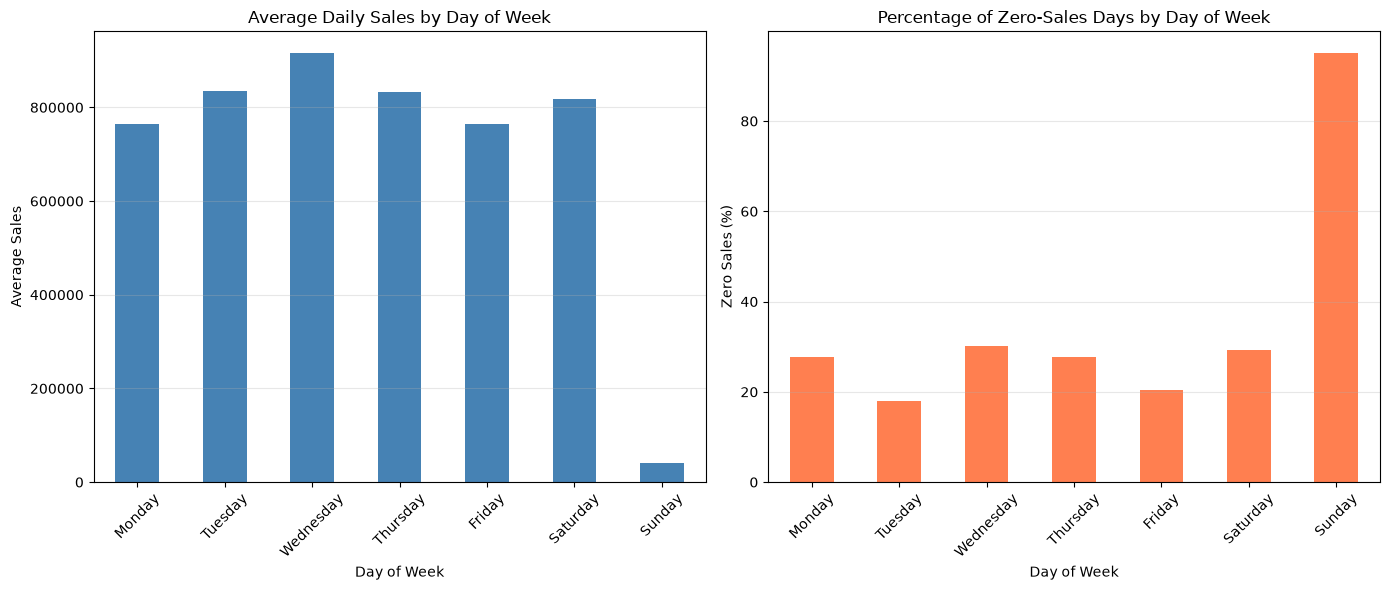

In [31]:
# Check if Sunday sales are always zero

# For daily data, check which day of the week has zero sales
daily_by_weekday = daily_df.copy()
daily_by_weekday['weekday'] = daily_by_weekday.index.dayofweek
daily_by_weekday['weekday_name'] = daily_by_weekday.index.day_name()

print("=" * 80)
print("DAILY SALES BY DAY OF WEEK")
print("=" * 80)

# Summary statistics by day of week
weekday_summary = daily_by_weekday.groupby('weekday_name')['sales'].agg([
    'count', 
    'sum', 
    'mean', 
    'median',
    ('zero_count', lambda x: (x == 0).sum()),
    ('non_zero_count', lambda x: (x > 0).sum())
])

# Reorder to start with Monday
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_summary = weekday_summary.reindex([d for d in day_order if d in weekday_summary.index])

print("\nSummary by day of week:")
display(weekday_summary)

# Calculate percentage of zero sales days
weekday_summary['zero_percentage'] = (weekday_summary['zero_count'] / weekday_summary['count'] * 100).round(2)
print("\nPercentage of zero-sales days:")
display(weekday_summary[['zero_count', 'count', 'zero_percentage']])

# Check specifically for Sundays
sunday_sales = daily_by_weekday[daily_by_weekday['weekday_name'] == 'Sunday']['sales']
print("\n" + "=" * 80)
print("SUNDAY-SPECIFIC ANALYSIS")
print("=" * 80)
print(f"Total Sundays: {len(sunday_sales)}")
print(f"Sundays with zero sales: {(sunday_sales == 0).sum()}")
print(f"Sundays with non-zero sales: {(sunday_sales > 0).sum()}")
print(f"Percentage of Sundays with zero sales: {(sunday_sales == 0).sum() / len(sunday_sales) * 100:.2f}%")

if (sunday_sales > 0).any():
    print("\nSundays with NON-ZERO sales:")
    non_zero_sundays = daily_by_weekday[
        (daily_by_weekday['weekday_name'] == 'Sunday') & 
        (daily_by_weekday['sales'] > 0)
    ][['sales']]
    display(non_zero_sundays)
else:
    print("\n✓ ALL SUNDAYS have ZERO sales")

# Visualization
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
weekday_avg = daily_by_weekday.groupby('weekday_name')['sales'].mean().reindex(day_order)
weekday_avg.plot(kind='bar', color='steelblue')
plt.title('Average Daily Sales by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Sales')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.subplot(1, 2, 2)
zero_pct = (daily_by_weekday.groupby('weekday_name')['sales'].apply(lambda x: (x == 0).sum() / len(x) * 100)).reindex(day_order)
zero_pct.plot(kind='bar', color='coral')
plt.title('Percentage of Zero-Sales Days by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Zero Sales (%)')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

WEEKLY SALES PATTERN ANALYSIS

1. OVERALL WEEKLY STATISTICS
--------------------------------------------------------------------------------


count    8.200000e+01
mean     5.005179e+06
std      8.767173e+06
min      0.000000e+00
25%      3.492731e+05
50%      2.030684e+06
75%      6.103794e+06
max      6.396721e+07
Name: sales, dtype: float64


Weeks with zero sales: 3
Weeks with non-zero sales: 79
Percentage of zero-sales weeks: 3.66%

2. WEEKS WITH ZERO SALES
--------------------------------------------------------------------------------


,sales,rain_sum_week,rainy_days
week_ending,,,
2025-10-05,0.0,24.8,7
2026-07-12,0.0,92.2,7
2026-08-02,0.0,234.6,7



Average rainfall in zero-sales weeks: 117.20 mm
Average rainy days in zero-sales weeks: 7.00 days

3. MONTHLY SALES PATTERN
--------------------------------------------------------------------------------


,count,sum,mean,median,zero_count,min,max
month,,,,,,,
2025-01,3,3.444189e+07,1.148063e+07,7178815.12,0,198122.40,27064954.68
2025-02,4,1.094518e+08,2.736296e+07,15341341.50,0,14801949.52,63967214.68
2025-03,5,4.194672e+07,8.389343e+06,6615171.52,0,4170065.72,19326220.14
2025-04,4,2.722885e+07,6.807213e+06,6680514.60,0,5082371.66,8785451.08
2025-05,4,1.708571e+07,4.271428e+06,3829811.64,0,3111636.02,6314452.50
2025-06,5,1.052993e+07,2.105986e+06,1705824.22,0,929426.42,3291967.88
2025-07,4,4.194300e+06,1.048575e+06,1064843.92,0,346347.50,1718264.98
2025-08,5,3.233035e+06,6.466070e+05,467976.62,0,165748.32,1330890.78
2025-09,4,9.284935e+05,2.321234e+05,272791.83,0,24198.30,358711.52



4. QUARTERLY SALES PATTERN
--------------------------------------------------------------------------------


,count,sum,mean,zero_count
quarter,,,,
2025Q1,12,1.858405e+08,1.548670e+07,0
2025Q2,13,5.484449e+07,4.218807e+06,0
2025Q3,13,8.355829e+06,6.427561e+05,0
2025Q4,13,3.252911e+06,2.502239e+05,1
2026Q1,13,1.190423e+08,9.157101e+06,0
2026Q2,13,3.533453e+07,2.718040e+06,0
2026Q3,5,3.754150e+06,7.508300e+05,2


TypeError: Axes.boxplot() got an unexpected keyword argument 'labels'. Did you mean 'label'?

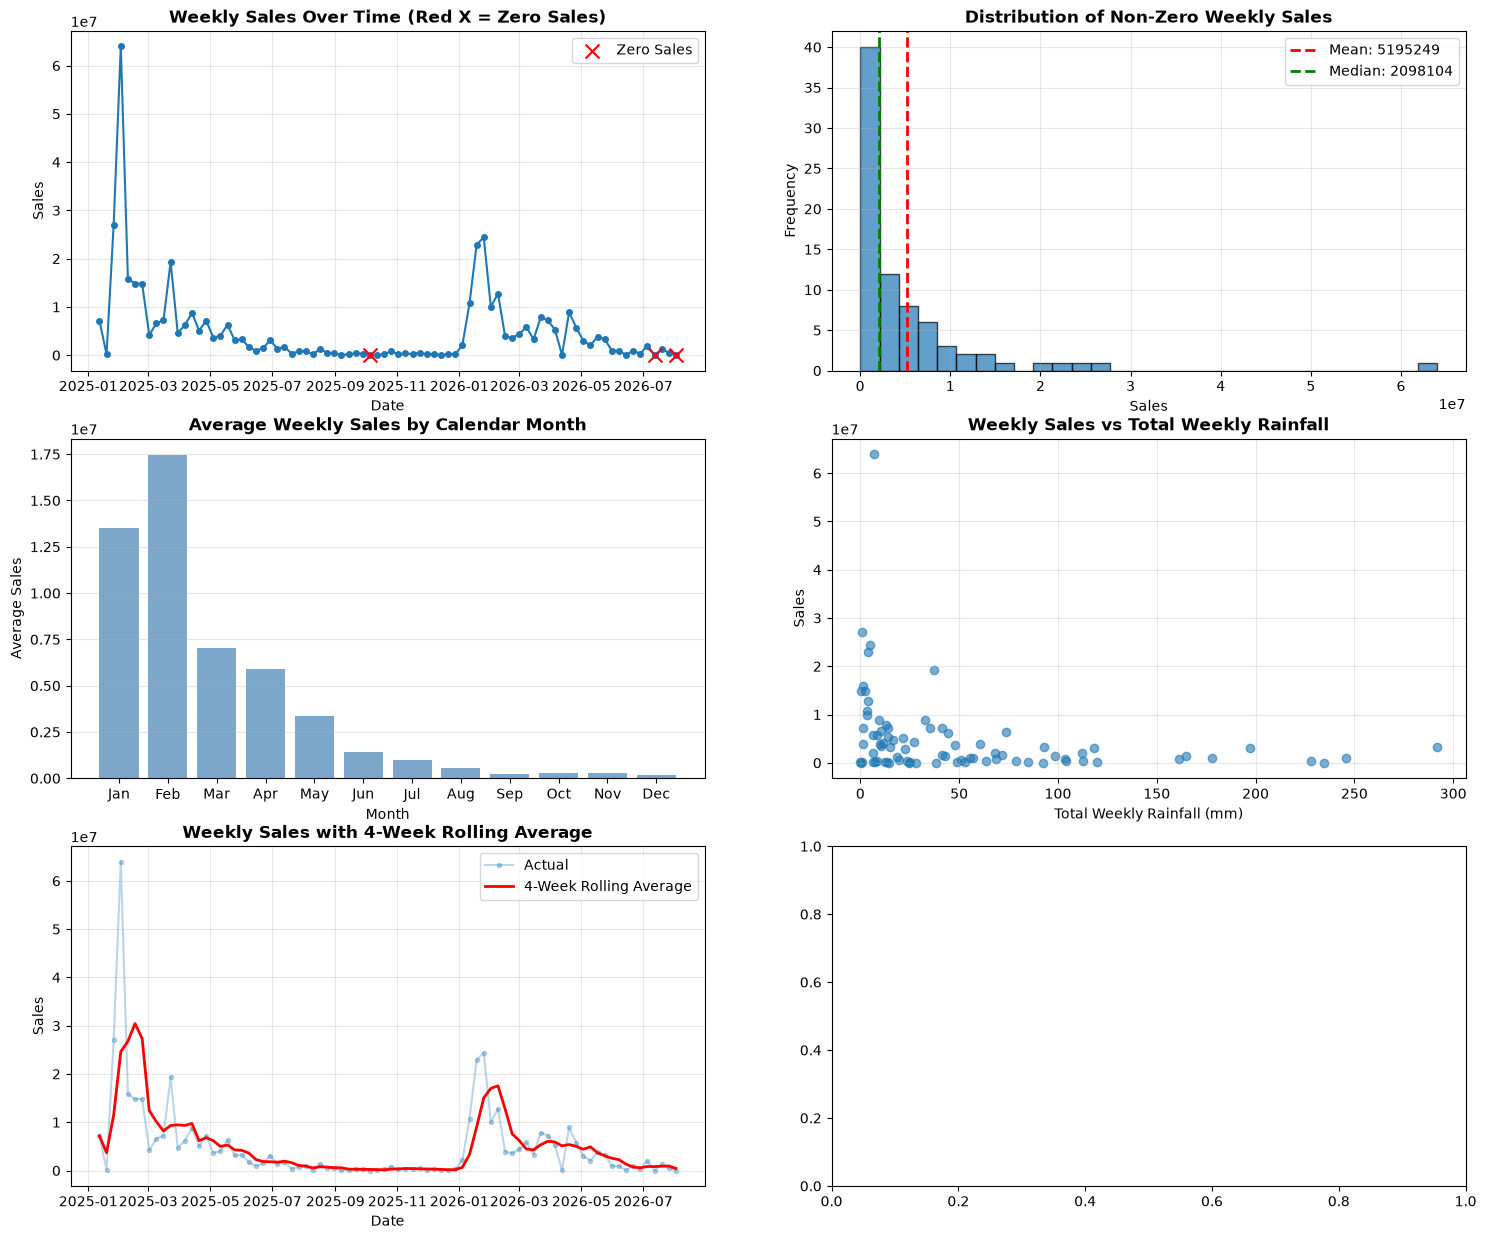

In [33]:
## Analysis of Weekly Sales Patterns

#Let's examine the weekly sales patterns in detail:


# Comprehensive weekly pattern analysis
print("=" * 80)
print("WEEKLY SALES PATTERN ANALYSIS")
print("=" * 80)

# Basic statistics
print("\n1. OVERALL WEEKLY STATISTICS")
print("-" * 80)
weekly_stats = weekly_df['sales'].describe()
display(weekly_stats)

# Check for zero sales weeks
zero_weeks = (weekly_df['sales'] == 0).sum()
non_zero_weeks = (weekly_df['sales'] > 0).sum()
print(f"\nWeeks with zero sales: {zero_weeks}")
print(f"Weeks with non-zero sales: {non_zero_weeks}")
print(f"Percentage of zero-sales weeks: {zero_weeks / len(weekly_df) * 100:.2f}%")

# Identify weeks with zero sales
if zero_weeks > 0:
    print("\n2. WEEKS WITH ZERO SALES")
    print("-" * 80)
    zero_sales_weeks = weekly_df[weekly_df['sales'] == 0][['sales', 'rain_sum_week', 'rainy_days']]
    display(zero_sales_weeks)
    
    # Check if there's a pattern with rainfall
    print(f"\nAverage rainfall in zero-sales weeks: {zero_sales_weeks['rain_sum_week'].mean():.2f} mm")
    print(f"Average rainy days in zero-sales weeks: {zero_sales_weeks['rainy_days'].mean():.2f} days")

# Monthly aggregation to see seasonal patterns
print("\n3. MONTHLY SALES PATTERN")
print("-" * 80)
monthly_sales = weekly_df.copy()
monthly_sales['month'] = monthly_sales.index.to_period('M')
monthly_summary = monthly_sales.groupby('month')['sales'].agg([
    'count', 'sum', 'mean', 'median', 
    ('zero_count', lambda x: (x == 0).sum()),
    'min', 'max'
])
display(monthly_summary)

# Quarterly pattern
print("\n4. QUARTERLY SALES PATTERN")
print("-" * 80)
quarterly_sales = weekly_df.copy()
quarterly_sales['quarter'] = quarterly_sales.index.to_period('Q')
quarterly_summary = quarterly_sales.groupby('quarter')['sales'].agg([
    'count', 'sum', 'mean', 
    ('zero_count', lambda x: (x == 0).sum())
])
display(quarterly_summary)

# Visualizations
fig, axes = plt.subplots(3, 2, figsize=(18, 15))

# 1. Weekly sales time series with zero sales highlighted
ax = axes[0, 0]
ax.plot(weekly_df.index, weekly_df['sales'], marker='o', linewidth=1.5, markersize=4)
zero_weeks_mask = weekly_df['sales'] == 0
ax.scatter(weekly_df.index[zero_weeks_mask], 
          weekly_df['sales'][zero_weeks_mask], 
          color='red', s=100, zorder=5, label='Zero Sales', marker='x')
ax.set_title('Weekly Sales Over Time (Red X = Zero Sales)', fontsize=12, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Sales')
ax.legend()
ax.grid(True, alpha=0.3)

# 2. Distribution of weekly sales (excluding zeros)
ax = axes[0, 1]
non_zero_sales = weekly_df[weekly_df['sales'] > 0]['sales']
ax.hist(non_zero_sales, bins=30, edgecolor='black', alpha=0.7)
ax.axvline(non_zero_sales.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {non_zero_sales.mean():.0f}')
ax.axvline(non_zero_sales.median(), color='green', linestyle='--', linewidth=2, label=f'Median: {non_zero_sales.median():.0f}')
ax.set_title('Distribution of Non-Zero Weekly Sales', fontsize=12, fontweight='bold')
ax.set_xlabel('Sales')
ax.set_ylabel('Frequency')
ax.legend()
ax.grid(True, alpha=0.3)

# 3. Monthly average sales
ax = axes[1, 0]
monthly_avg = monthly_sales.groupby(monthly_sales.index.month)['sales'].mean()
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
ax.bar(range(1, 13), [monthly_avg.get(i, 0) for i in range(1, 13)], color='steelblue', alpha=0.7)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names)
ax.set_title('Average Weekly Sales by Calendar Month', fontsize=12, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Average Sales')
ax.grid(True, alpha=0.3, axis='y')

# 4. Rainfall vs Sales scatter plot
ax = axes[1, 1]
ax.scatter(weekly_df['rain_sum_week'], weekly_df['sales'], alpha=0.6)
ax.set_title('Weekly Sales vs Total Weekly Rainfall', fontsize=12, fontweight='bold')
ax.set_xlabel('Total Weekly Rainfall (mm)')
ax.set_ylabel('Sales')
ax.grid(True, alpha=0.3)

# 5. Rolling 4-week average
ax = axes[2, 0]
rolling_avg = weekly_df['sales'].rolling(window=4, min_periods=1).mean()
ax.plot(weekly_df.index, weekly_df['sales'], alpha=0.3, label='Actual', marker='o', markersize=3)
ax.plot(weekly_df.index, rolling_avg, linewidth=2, label='4-Week Rolling Average', color='red')
ax.set_title('Weekly Sales with 4-Week Rolling Average', fontsize=12, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Sales')
ax.legend()
ax.grid(True, alpha=0.3)

# 6. Box plot by quarter
ax = axes[2, 1]
quarters_list = [weekly_df[weekly_df.index.to_period('Q') == q]['sales'].values 
                 for q in quarterly_sales['quarter'].unique()]
ax.boxplot(quarters_list, labels=[str(q) for q in quarterly_sales['quarter'].unique()])
ax.set_title('Weekly Sales Distribution by Quarter', fontsize=12, fontweight='bold')
ax.set_xlabel('Quarter')
ax.set_ylabel('Sales')
ax.tick_params(axis='x', rotation=45)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Check for any cyclical patterns (every N weeks)
print("\n5. CHECKING FOR CYCLICAL PATTERNS")
print("-" * 80)
for period in [4, 13, 26, 52]:
    if len(weekly_df) >= period:
        autocorr = weekly_df['sales'].autocorr(lag=period)
        print(f"Autocorrelation at lag {period} weeks (~{period/4.33:.1f} months): {autocorr:.4f}")

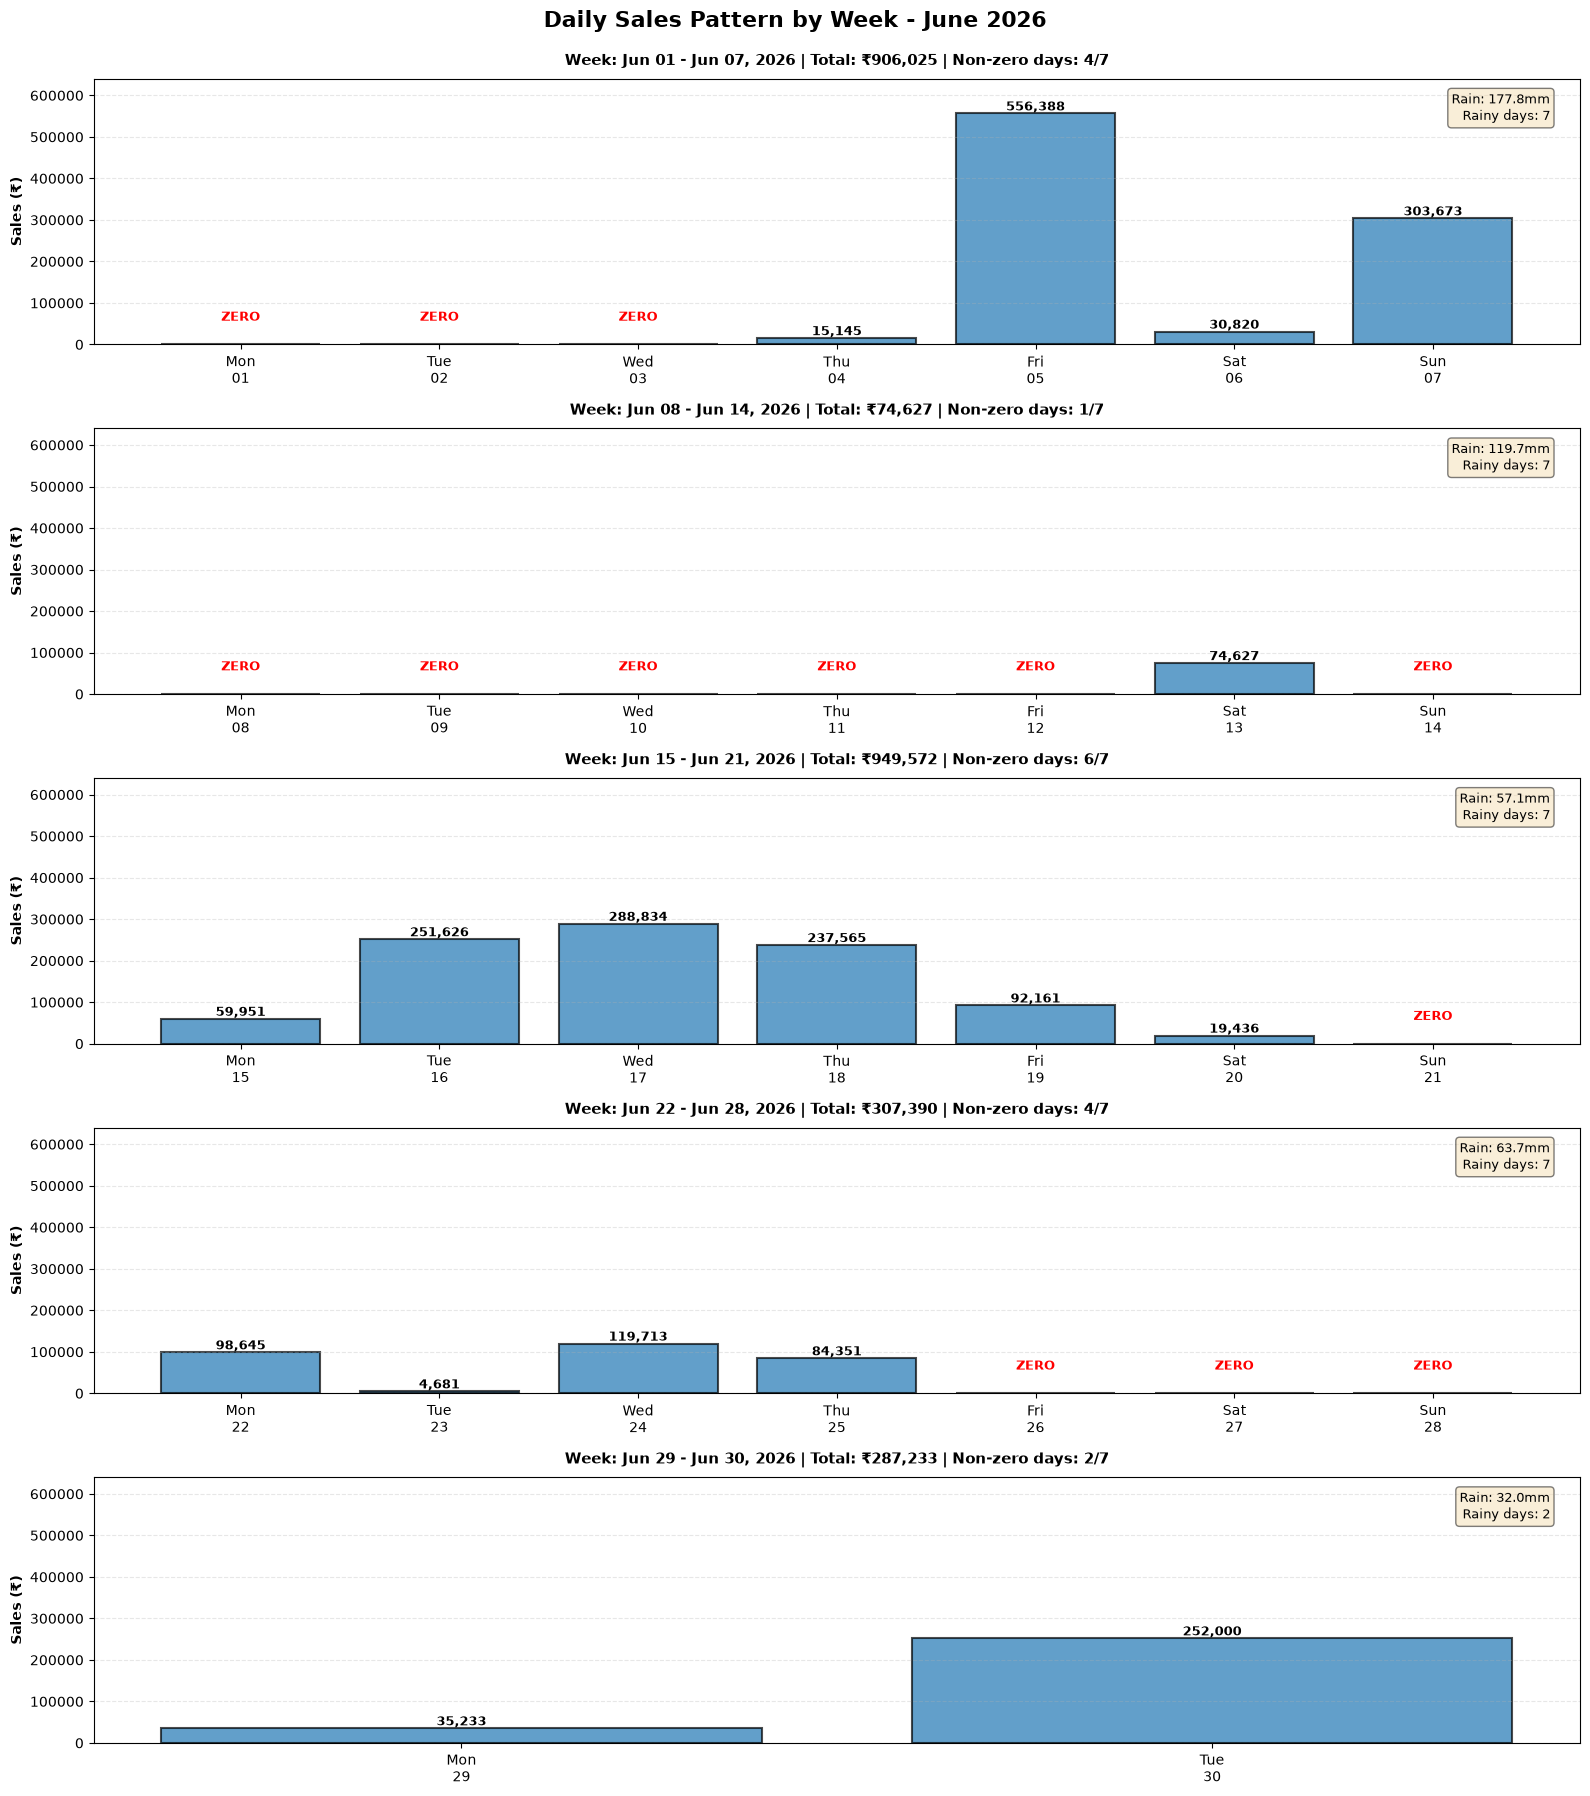

JUNE 2026 DAILY SALES SUMMARY

Total sales: ₹2,524,845.86
Average daily sales: ₹84,161.53
Median daily sales: ₹17,290.35
Days with zero sales: 13 out of 30
Days with non-zero sales: 17 out of 30

Total rainfall: 450.3 mm
Rainy days: 30 out of 30

--------------------------------------------------------------------------------
SALES BY DAY OF WEEK IN JUNE 2026
--------------------------------------------------------------------------------


,count,sum,mean,zero_count
day_name,,,,
Monday,5,193828.96,38765.792,2
Tuesday,5,508307.12,101661.424,2
Wednesday,4,408546.60,102136.650,2
Thursday,4,337060.52,84265.130,1
Friday,4,648548.28,162137.070,2
Saturday,4,124881.78,31220.445,1
Sunday,4,303672.60,75918.150,3


In [34]:
# Graph of daily sales for all weeks in June 2026
import matplotlib.pyplot as plt

# Filter June 2026 data
june_2026 = daily_df[daily_df.index.to_period('M') == '2026-06']

# Create figure with subplots for each week
fig, axes = plt.subplots(5, 1, figsize=(16, 18))
fig.suptitle('Daily Sales Pattern by Week - June 2026', fontsize=16, fontweight='bold', y=0.995)

# Get all weeks in June 2026
june_weeks = june_2026.index.to_period('W').unique().sort_values()

for idx, week in enumerate(june_weeks):
    if idx >= 5:  # Safety check
        break
    
    ax = axes[idx]
    
    # Get data for this week
    week_data = june_2026[june_2026.index.to_period('W') == week]
    
    # Create bar chart
    bars = ax.bar(range(len(week_data)), week_data['sales'], 
                   color=['#1f77b4' if s > 0 else '#d62728' for s in week_data['sales']],
                   alpha=0.7, edgecolor='black', linewidth=1.5)
    
    # Set x-axis labels to day names
    ax.set_xticks(range(len(week_data)))
    ax.set_xticklabels([d.strftime('%a\n%d') for d in week_data.index], fontsize=10)
    
    # Add value labels on bars
    for i, (date, sales) in enumerate(zip(week_data.index, week_data['sales'])):
        if sales > 0:
            ax.text(i, sales, f'{sales:,.0f}', 
                   ha='center', va='bottom', fontsize=9, fontweight='bold')
        else:
            ax.text(i, 50000, 'ZERO', ha='center', va='bottom', 
                   fontsize=9, fontweight='bold', color='red')
    
    # Week summary
    week_start = week_data.index.min().strftime('%b %d')
    week_end = week_data.index.max().strftime('%b %d, %Y')
    week_total = week_data['sales'].sum()
    non_zero_days = (week_data['sales'] > 0).sum()
    
    ax.set_title(f'Week: {week_start} - {week_end} | Total: ₹{week_total:,.0f} | Non-zero days: {non_zero_days}/7',
                fontsize=11, fontweight='bold', pad=10)
    ax.set_ylabel('Sales (₹)', fontsize=10, fontweight='bold')
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    ax.set_ylim(0, june_2026['sales'].max() * 1.15)
    
    # Add rainfall info as text box
    week_rain = week_data['rain_sum'].sum()
    rainy_days = week_data['rainy_day'].sum()
    textstr = f'Rain: {week_rain:.1f}mm\nRainy days: {rainy_days}'
    ax.text(0.98, 0.95, textstr, transform=ax.transAxes, fontsize=9,
           verticalalignment='top', horizontalalignment='right',
           bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

# Print summary statistics
print("=" * 80)
print("JUNE 2026 DAILY SALES SUMMARY")
print("=" * 80)
print(f"\nTotal sales: ₹{june_2026['sales'].sum():,.2f}")
print(f"Average daily sales: ₹{june_2026['sales'].mean():,.2f}")
print(f"Median daily sales: ₹{june_2026['sales'].median():,.2f}")
print(f"Days with zero sales: {(june_2026['sales'] == 0).sum()} out of {len(june_2026)}")
print(f"Days with non-zero sales: {(june_2026['sales'] > 0).sum()} out of {len(june_2026)}")
print(f"\nTotal rainfall: {june_2026['rain_sum'].sum():.1f} mm")
print(f"Rainy days: {june_2026['rainy_day'].sum()} out of {len(june_2026)}")

# Day of week analysis for June
print("\n" + "-" * 80)
print("SALES BY DAY OF WEEK IN JUNE 2026")
print("-" * 80)
june_by_day = june_2026.copy()
june_by_day['day_name'] = june_by_day.index.day_name()
day_summary = june_by_day.groupby('day_name')['sales'].agg(['count', 'sum', 'mean', 
                                                             ('zero_count', lambda x: (x == 0).sum())])
day_summary = day_summary.reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])
display(day_summary)